# Lab 4, Notebook B - Aligning point clouds

*Linear Algebra for Data Science, UCU 2026. Uses Session 5.2 (the SVD, orthogonal Procrustes $Q = UV^\top$, the Kabsch sign fix) and, for B3(d), PCA from Session 5.1.*

A 3-D scanner, a depth camera or a robot's lidar sees an object in its own coordinate system. Before two scans can be compared, merged or used to locate the robot, they must be brought into one frame by a **rigid motion**: a rotation and a translation. When we know which point corresponds to which, the best rotation comes from one $3\times3$ SVD (B1). When the data are nearly flat, that SVD can return a mirror image instead of a rotation, and we must forbid it (B2). When we do not know the correspondences at all, we guess them, align, and guess again: the **iterative closest point** algorithm (B3). Each step of ICP is the problem of B1.

**Convention (as in Lecture 5.2 and the notes).** Points are the **rows** of a matrix. A rigid motion maps the rows of $X$ to the rows of $XQ + \mathbf 1\mathbf t^\top$, with $Q$ orthogonal and $\mathbf t\in\mathbb R^3$. On a single **column** vector $\mathbf x$ the same motion is $\mathbf x\mapsto Q^\top\mathbf x + \mathbf t$. If $X^\top Y = U\Sigma V^\top$ (both clouds centred), the best orthogonal $Q$ is $UV^\top$.

**How to work.** Most tasks ask you to **predict first, in writing, then compute, then explain any difference**. Write the prediction *before* running the cell. A wrong prediction with an honest explanation earns more at the defence than a correct number you cannot explain.

**Rules.**
- Do not call `np.linalg.inv` or `np.linalg.pinv` anywhere.
- Compute every rotation with `np.linalg.svd` on a $3\times3$ matrix. `scipy.linalg.orthogonal_procrustes` and `scipy.spatial.transform.Rotation` are allowed only where a cell says **check**.
- Find nearest neighbours with `scipy.spatial.cKDTree`.
- Do not change the seeds.
- Before you submit, run `Kernel -> Restart & Run All`.

**Marking.** Core B is worth 2 points at the defence; the code point and the extension are shared with Notebook A.

**Contents.** B1 Procrustes with known correspondences | B2 When the best fit is a mirror: Kabsch | B3 Unknown correspondences: ICP | Extension E2 (shape from a moving camera: Tomasi-Kanade). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Vladyslav Hryhola* |
| **Team member 2** | *Ihor Kashuba* |
| **Extension attempted** (at most one in the whole lab) | *none / E1 / E2* |
| **Late days used on this lab** | *1* |
| **Runs top to bottom from a clean kernel** | *yes* |

python 3.13.18 | numpy 2.4.6 | scipy 1.16.3 | matplotlib 3.10.0
model: (800, 3)  centred singular values / sqrt(n): [1.3033 0.5768 0.3731]


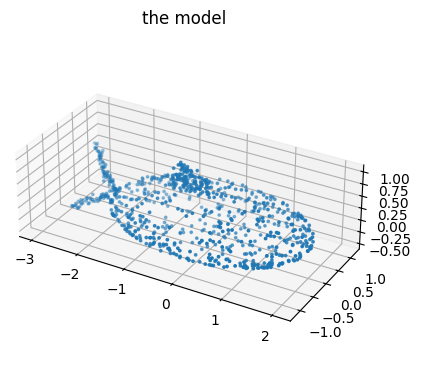

In [1]:
import sys, time
import numpy as np
import scipy, scipy.linalg as sl
from scipy.spatial import cKDTree
import matplotlib, matplotlib.pyplot as plt

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)
np.set_printoptions(precision=4, suppress=True, linewidth=110)


def make_fish(n, seed):
    # n points on the surface of an asymmetric 'fish': an ellipsoid body, a fin on top, a forked tail bent to one side
    rng = np.random.default_rng(seed)
    nb, nf = int(0.7 * n), int(0.15 * n); nt = n - nb - nf
    z = rng.standard_normal((nb, 3)); z /= np.linalg.norm(z, axis=1, keepdims=True)
    body = z * np.array([2.0, 1.2, 0.5])
    a, b = rng.random(nf), rng.random(nf); m = a + b > 1; a[m], b[m] = 1 - a[m], 1 - b[m]
    P0, P1, P2 = np.array([0.3, 0, 0.5]), np.array([-0.9, 0, 0.45]), np.array([-0.6, 0, 1.1])
    fin = P0 + a[:, None] * (P1 - P0) + b[:, None] * (P2 - P0) + 0.03 * rng.standard_normal((nf, 3))
    s = rng.random(nt); side = np.where(rng.random(nt) < 0.5, 1, -1)
    tail = np.c_[-2.0 - 0.9 * s, 0.25 * s + 0.5 * side * s ** 1.5, 0.45 * side * s] + 0.04 * rng.standard_normal((nt, 3))
    return np.vstack([body, fin, tail])


def rot(axis, deg):
    # rotation by deg degrees about axis, ACTING ON COLUMN VECTORS: x -> R x (Rodrigues' formula)
    k = np.asarray(axis, float); k /= np.linalg.norm(k); th = np.deg2rad(deg)
    K = np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def angle_deg(Q):
    # rotation angle of a 3x3 rotation matrix, in degrees: trace Q = 1 + 2 cos(angle)
    return np.degrees(np.arccos(np.clip((np.trace(Q) - 1) / 2, -1, 1)))


def rms(A, B):
    # root-mean-square distance between corresponding rows of A and B
    return np.sqrt(np.mean(np.sum((A - B) ** 2, axis=1)))


def show(*clouds, labels=None, title=""):
    fig = plt.figure(figsize=(5.5, 4)); ax = fig.add_subplot(projection="3d")
    for i, C in enumerate(clouds):
        ax.scatter(*C.T, s=3, label=None if labels is None else labels[i])
    ax.set_box_aspect(np.ptp(np.vstack(clouds), axis=0)); ax.set_title(title)
    if labels: ax.legend()
    plt.tight_layout(); plt.show()


X = make_fish(800, seed=1)            # the model: 800 points, rows are points
n = len(X)
print("model:", X.shape, " centred singular values / sqrt(n):", np.linalg.svd(X - X.mean(0), compute_uv=False) / np.sqrt(n))
show(X, title="the model")

---
## B1. Procrustes with known correspondences

A scanner has measured the same 800 points, in the same order, after the fish was moved. The manual says the motion was the rotation $R$ by $40^\circ$ about the axis $(1,2,2)$, acting on column vectors as $\mathbf x\mapsto R\mathbf x$, followed by the shift $\mathbf t = (5,-2,1)$. The measurements carry noise of size $\text{sd} = 0.02$ per coordinate.

**(a)** In our row convention the planted motion is $Y = XQ_{\text{true}} + \mathbf 1\mathbf t^\top + E$. Which matrix is $Q_{\text{true}}$, in terms of $R$? Then implement `procrustes(X, Y)`, which centres both clouds, computes the SVD of the $3\times3$ matrix $\widetilde X^\top\widetilde Y$, and returns $Q = UV^\top$, the translation $\mathbf t$, and the singular values. (Section 2 of Tutorial 5.2 proves that $UV^\top$ is optimal; here you only use it.)

In [2]:
R_true = rot([1, 2, 2], 40)
t_true = np.array([5.0, -2.0, 1.0])
sd = 0.02

In [3]:
Q_true = R_true.T   # rows convention: (R x)^T = x^T R^T, so the row-matrix is R^T

def procrustes(X, Y):
    # returns Q (orthogonal), t, s (singular values of the centred X'Y) with  X Q + 1 t' ~ Y
    # 1. centre both clouds (subtract the centroid)
    mu_X = X.mean(axis=0)
    mu_Y = Y.mean(axis=0)
    X_cen = X - mu_X
    Y_cen = Y - mu_Y

    # 2. SVD of the 3x3 cross-covariance matrix H = X~^T Y~ (numpy returns V^T, called Vt)
    H = X_cen.T @ Y_cen
    U, s, Vt = np.linalg.svd(H)

    # 3. the optimal orthogonal matrix is Q = U V^T
    Q = U @ Vt
    # 4. translation: the rotated centroid of X must land on the centroid of Y
    t = mu_Y - mu_X @ Q

    return Q, t, s

In [4]:
# check
Y = X @ Q_true + t_true + sd * np.random.default_rng(2).standard_normal(X.shape)
Q, t, s = procrustes(X, Y)
R_sp, _ = sl.orthogonal_procrustes(X - X.mean(0), Y - Y.mean(0))
assert np.allclose(Q, R_sp) and np.allclose(Q.T @ Q, np.eye(3))
print(f"det Q = {np.linalg.det(Q):+.0f};  rotation error {angle_deg(Q @ Q_true.T):.3f} deg;  "
      f"translation error {np.linalg.norm(t - t_true):.4f}")

det Q = +1;  rotation error 0.064 deg;  translation error 0.0014


**(b)** *Predict, then compute.* Lecture 5.2 gives the minimal value
$$\min_Q\|\widetilde XQ - \widetilde Y\|_F^2 = \|\widetilde X\|_F^2 + \|\widetilde Y\|_F^2 - 2(\sigma_1+\sigma_2+\sigma_3).$$
Predict two things before running: whether the residual of your fit will equal this formula exactly or only approximately, and the size of the **mean squared residual per point**, $\frac1n\|XQ + \mathbf 1\mathbf t^\top - Y\|_F^2$, in terms of $\text{sd}$. Then compute both.

**Your prediction** *(write it before running the next cell)*: The residual of my fit will equal the formula exactly, up to floating-point rounding, because the formula is the minimum of the Frobenius norm over all orthogonal Q, and the optimal translation makes the centroids coincide. The mean squared residual per point will be approximately 3·sd² = 3·0.02² = 0.0012, since the noise has variance sd² in each of the 3 coordinates of a point.

In [5]:
Q, t, s = procrustes(X, Y)
Xc, Yc = X - X.mean(0), Y - Y.mean(0)

# actual residual of the fit
actual_residual = np.sum((X @ Q + t - Y) ** 2)
# residual predicted by the formula from Lecture 5.2
formula_residual = np.sum(Xc ** 2) + np.sum(Yc ** 2) - 2 * np.sum(s)

print(f"Actual residual:  {actual_residual:.6f}")
print(f"Formula residual: {formula_residual:.6f}")
print(f"Difference:       {abs(actual_residual - formula_residual):.2e}")
print(f"||Xc||^2 = {np.sum(Xc**2):.1f},  ||Yc||^2 = {np.sum(Yc**2):.1f},  2*sum(s) = {2*np.sum(s):.1f}")

mse = np.mean(np.sum((X @ Q + t - Y) ** 2, axis=1))
print(f"Mean squared residual per point: {mse:.6f} (prediction: 0.0012)")

Actual residual:  0.957480
Formula residual: 0.957480
Difference:       9.85e-13
||Xc||^2 = 1736.4,  ||Yc||^2 = 1738.6,  2*sum(s) = 3474.0
Mean squared residual per point: 0.001197 (prediction: 0.0012)


**Your answer.**
The computed residual equals the formula up to rounding, as predicted: the difference is about 10⁻¹² (9.85·10⁻¹³ in our run). This is numerical noise: the formula subtracts 2Σσ ≈ 3474 from ‖X̃‖² + ‖Ỹ‖² ≈ 3475, so rounding errors of these large numbers remain, while the result itself is only 0.957.

The mean squared residual per point is ≈ 0.001197, close to my prediction 0.0012, but slightly smaller, which I did not predict. The reason: the fit has 6 free parameters (3 for the rotation, 3 for the translation), so it adjusts to the noise and absorbs a small part of it. The expected size of this effect is about 3·sd²·(1 − 6/(3n)) ≈ 0.001197, which matches the measured value.

**(c)** *Why centre?* Run your SVD **without** centring, on $X^\top Y$ itself, and report the rotation error of $UV^\top$. Explain the failure by writing $X^\top Y$ in terms of $\widetilde X^\top\widetilde Y$ and the two means.

In [6]:
U_uc, s_uc, Vt_uc = np.linalg.svd(X.T @ Y)
Q_uc = U_uc @ Vt_uc
print(f"Rotation error without centring: {angle_deg(Q_uc @ Q_true.T):.3f} deg")
Xc, Yc = X - X.mean(0), Y - Y.mean(0)
H_correct = Xc.T @ Yc                                  # the useful term
H_extra = len(X) * np.outer(X.mean(0), Y.mean(0))      # the rank-one term n * xbar * ybar^T
print(f"||Xc^T Yc||_F = {np.linalg.norm(H_correct):.0f},  ||n xbar ybar^T||_F = {np.linalg.norm(H_extra):.0f}")
print("identity X^T Y = Xc^T Yc + n xbar ybar^T holds:", np.allclose(X.T @ Y, H_correct + H_extra))

Rotation error without centring: 64.196 deg
||Xc^T Yc||_F = 1389,  ||n xbar ybar^T||_F = 1794
identity X^T Y = Xc^T Yc + n xbar ybar^T holds: True


**Your answer.** Without centring, SVD of XᵀY gives a rotation error of 64.2° (against 0.06° with centring).

Writing X = X̃ + 1x̄ᵀ and Y = Ỹ + 1ȳᵀ, and using 1ᵀX̃ = 0 and 1ᵀ1 = n, the cross terms vanish, and
XᵀY = X̃ᵀỸ + n·x̄ȳᵀ.
The second term is a rank-one matrix, dominated by the large translation (ȳ ≈ x̄Q + t, with t = (5, −2, 1)); it carries no information about the rotation of the fish. Its norm (1794) is even larger than that of the useful term X̃ᵀỸ (1389), so it contaminates the singular vectors, and UVᵀ is no longer the optimal rotation.

**(d)** *Orientation.* Implement `move(P, Q, t)` for a matrix of points in rows. Then a teammate writes the motion for one column vector as `Q @ x + t`. Compute the RMS distance between the moved model and $Y$ with the teammate's version, `X @ Q.T + t`, and with yours. Which motion does the teammate's code apply, and by how many degrees is it off?

In [7]:
def move(P, Q, t):
    # points are rows: rotate by multiplying on the right, then translate
    return P @ Q + t

Q, t, s = procrustes(X, Y)           # the fit from (a)
Y_mine = move(X, Q, t)               # correct row convention
Y_team = X @ Q.T + t                 # teammate's version (column formula applied to rows)

print(f"RMS distance (mine):     {rms(Y_mine, Y):.4f}")
print(f"RMS distance (teammate): {rms(Y_team, Y):.4f}")
print(f"noise level sqrt(3)*sd = {np.sqrt(3) * sd:.4f};  RMS radius of the fish = "
      f"{np.sqrt(np.mean(np.sum((X - X.mean(0)) ** 2, axis=1))):.2f}")
# relative rotation between Q and Q^T is Q (Q^T)^T = Q Q
print(f"Angle between the two rotations: {angle_deg(Q @ Q):.1f} degrees")

RMS distance (mine):     0.0346
RMS distance (teammate): 1.8033
noise level sqrt(3)*sd = 0.0346;  RMS radius of the fish = 1.47
Angle between the two rotations: 80.0 degrees


**Your answer.** With my move (rows multiplied by Q on the right) the RMS distance to Y is 0.035, which equals the noise level √3·sd = 0.0346. With the teammate’s X @ Q.T + t it is 1.80, larger than the size of the fish (RMS radius ≈ 1.47).

The teammate’s code applies Qᵀ = Q⁻¹ to the rows, i.e. the rotation by 40° in the opposite direction (it treats a row vector as if it were a column vector). The angle between the correct and the applied rotation is 2·40° = 80°, which is what angle_deg(Q @ Q) shows.

**(e)** *Predict, then compute.* How should the rotation error scale with the noise level and with the number of points? Predict a formula of the form $\text{error} \propto \text{sd}^a n^b$. Then measure the mean rotation error over 20 noise draws (seeds `100, ..., 119`) for $n = 10, 100, 1000, 10\,000$ points (`make_fish(n, seed=1)`) and $\text{sd} = 0.01, 0.1$. Fit $a$ and $b$ from the table.

**Your prediction** *(write it before running the next cell)*: The rotation error arises from the noise averaging out over the points. By the Central Limit Theorem, the error should be directly proportional to the noise level and inversely proportional to the square root of the number of points. Thus, the formula is error ∝ sd¹·n^(−0.5) (so a = 1, b = −0.5).

In [8]:
n_vals = [10, 100, 1000, 10000]
sd_vals = [0.01, 0.1]
seeds = range(100, 120)

mean_err = {}                                   # (n, sd) -> mean rotation error in degrees
for n_pts in n_vals:
    X_temp = make_fish(n_pts, seed=1)           # the model does not depend on sd or the noise seed
    for sd_ in sd_vals:
        errs = []
        for s_ in seeds:
            noise = np.random.default_rng(s_).standard_normal(X_temp.shape)
            Y_temp = X_temp @ Q_true + t_true + sd_ * noise
            Q_temp, _, _ = procrustes(X_temp, Y_temp)
            errs.append(angle_deg(Q_temp @ Q_true.T))
        mean_err[(n_pts, sd_)] = np.mean(errs)

print("  n      sd=0.01   sd=0.10")
for n_pts in n_vals:
    print(f"{n_pts:<6}   {mean_err[(n_pts, 0.01)]:.4f}    {mean_err[(n_pts, 0.1)]:.4f}")

# fit  log(error) = c0 + a*log(sd) + b*log(n)  by least squares
keys = list(mean_err)
A = np.array([[1.0, np.log(sd_), np.log(n_pts)] for n_pts, sd_ in keys])
y = np.log([mean_err[k] for k in keys])
coef, *_ = np.linalg.lstsq(A, y, rcond=None)
print(f"fitted: error ~ {np.exp(coef[0]):.1f} * sd^{coef[1]:.3f} * n^{coef[2]:.3f}")

# ratios that support the answer
for n_pts in n_vals:
    print(f"n={n_pts}: error(sd=0.1) / error(sd=0.01) = {mean_err[(n_pts, 0.1)] / mean_err[(n_pts, 0.01)]:.2f}")
for n_lo, n_hi in [(10, 1000), (100, 10000)]:
    r = mean_err[(n_lo, 0.01)] / mean_err[(n_hi, 0.01)]
    print(f"error(n={n_lo}) / error(n={n_hi}) = {r:.2f}  ->  local exponent {-np.log10(r) / 2:.2f}")

  n      sd=0.01   sd=0.10
10       0.2931    2.8592
100      0.0970    0.9668
1000     0.0256    0.2557
10000    0.0104    0.1037
fitted: error ~ 87.5 * sd^0.997 * n^-0.492
n=10: error(sd=0.1) / error(sd=0.01) = 9.75
n=100: error(sd=0.1) / error(sd=0.01) = 9.97
n=1000: error(sd=0.1) / error(sd=0.01) = 9.99
n=10000: error(sd=0.1) / error(sd=0.01) = 10.00
error(n=10) / error(n=1000) = 11.46  ->  local exponent -0.53
error(n=100) / error(n=10000) = 9.35  ->  local exponent -0.49


**Your answer.** The least-squares fit of log(error) on log(sd) and log(n) gives error ≈ 87.5·sd^0.997·n^−0.492, close to my prediction a = 1, b = −½.

From the table: in every row, multiplying sd by 10 multiplies the error by about 10 (ratios 9.75 to 10.0), so a ≈ 1. Multiplying n by 100 divides the error by about 11 (from n = 10 to 1000) or about 9 (from n = 100 to 10 000), not exactly 10, so the local exponent varies between about −0.53 and −0.49 and the power law is only approximate. We did not investigate why.

Why a = 1 and b ≈ −½: the noise enters X̃ᵀỸ linearly; the sum of n independent noise terms grows like √n, while the useful part of X̃ᵀỸ grows like n, so the relative perturbation, and therefore the rotation error, scales like √n/n = n^(−1/2).

---
## B2. When the best fit is a mirror: Kabsch

In practice the scanner does not see the 800 surface points with known labels. Instead, six **fiducial markers** are glued to the flat metal plate the fish lies on, at known positions $M$ in the model frame. The scanner finds the markers (noise $\text{sd} = 0.02$), Procrustes on the six markers gives the motion, and the motion is then applied to the whole model. The plate is flat up to a machining tolerance $h$: the markers' heights differ from the plane $z = -0.5$ by at most $h$.

In [9]:
def markers(h):
    xy = np.array([[1.5, 0.8], [1.2, -0.9], [-0.4, 1.0], [-1.0, -0.7], [-2.2, 0.3], [0.2, 0.1]])
    return np.c_[xy, -0.5 + h * np.array([1, -1, 0.5, -0.5, 0.2, -0.2])]

M = markers(0.01)
M_meas = M @ Q_true + t_true + 0.02 * np.random.default_rng(1003).standard_normal(M.shape)
truth = X @ Q_true + t_true          # where the fish really is
print("centred marker singular values:", np.linalg.svd(M - M.mean(0), compute_uv=False))

centred marker singular values: [3.1067 1.7254 0.0057]


**(a)** *Predict, then compute.* Run `procrustes(M, M_meas)`. Before running, predict whether $\det Q$ will be $+1$. Report $\det Q$, the RMS marker residual, and the RMS distance between the moved fish `move(X, Q, t)` and `truth`. Show both clouds with `show`. What has happened to the fish?

**Your prediction** *(write it before running the next cell)*: Because the markers are almost perfectly coplanar (flat) and the noise is relatively high, the SVD will likely interpret the Z-axis noise as a reflection. I predict det Q will be −1. The fish will appear flipped upside-down (mirrored).

det Q = -1
sigma_3 of the centred markers = 0.0057  (noise sd = 0.02)
RMS markers, fitted Q = 0.0276;  with the true motion = 0.0347
RMS fish vs truth = 1.3906


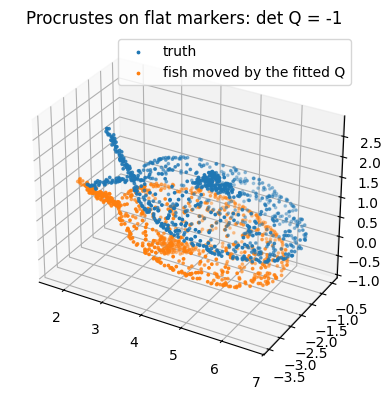

In [10]:
Q_m, t_m, s_m = procrustes(M, M_meas)
det_Q = np.linalg.det(Q_m)
rms_markers = rms(move(M, Q_m, t_m), M_meas)            # residual of the fitted motion
rms_markers_true = rms(move(M, Q_true, t_true), M_meas) # residual of the TRUE motion, for comparison
X_moved = move(X, Q_m, t_m)
rms_fish = rms(X_moved, truth)

print(f"det Q = {det_Q:+.0f}")
print(f"sigma_3 of the centred markers = {np.linalg.svd(M - M.mean(0), compute_uv=False)[2]:.4f}  (noise sd = 0.02)")
print(f"RMS markers, fitted Q = {rms_markers:.4f};  with the true motion = {rms_markers_true:.4f}")
print(f"RMS fish vs truth = {rms_fish:.4f}")
show(truth, X_moved, labels=["truth", "fish moved by the fitted Q"], title="Procrustes on flat markers: det Q = -1")

**Your answer.** det Q = −1: Procrustes returned a reflection, not a rotation. The RMS marker residual is 0.0276, which is even smaller than 0.0347 for the true motion, so the reflection fits the six markers better than the truth. But the fish moved by this Q is far from the truth: the RMS distance is 1.39, comparable to the size of the fish (RMS radius ≈ 1.47). The plot shows the fish mirrored in the plane of the markers.

The reason: the centred markers are almost flat, σ₃(M̃) ≈ 0.0057, which is smaller than the noise level 0.02, so the noise, not the geometry, decides the sign of the direction normal to the plate.

**(b)** Implement `kabsch(X, Y)`, which returns the best **rotation** ($\det Q = +1$) and translation: if $\det(UV^\top) = -1$, use $Q = U\operatorname{diag}(1, 1, -1)V^\top$ (Lecture 5.2, stated without proof). *Predict before running:* by how much will the **squared** marker residual increase compared with (a)? Use the statement in the lecture and the singular values printed in (a). Then compute the increase, the fish RMS and the rotation error.

**Your prediction** *(write it before running the next cell)*: To fix the reflection, we must flip the sign of the smallest singular value (σ₃). According to the minimal value formula from Lecture 5.2, changing −σ₃ to +σ₃ in the residual formula will increase the total squared residual by exactly 4σ₃(M̃).

In [11]:
def kabsch(X, Y):
    # like procrustes, but the result is forced to be a rotation (det Q = +1)
    Xc, Yc = X - X.mean(0), Y - Y.mean(0)
    U, s, Vt = np.linalg.svd(Xc.T @ Yc)
    if np.linalg.det(U @ Vt) < 0:
        U[:, -1] *= -1            # same as U @ diag(1, 1, -1): flips the direction of sigma_3
    Q = U @ Vt
    t = Y.mean(0) - X.mean(0) @ Q
    return Q, t

Q_k, t_k = kabsch(M, M_meas)
sq_res_procrustes = np.sum((move(M, Q_m, t_m) - M_meas) ** 2)
sq_res_kabsch = np.sum((move(M, Q_k, t_k) - M_meas) ** 2)
increase = sq_res_kabsch - sq_res_procrustes

print(f"det Q (Kabsch) = {np.linalg.det(Q_k):+.0f}")
print(f"sigma_3 of the cross matrix H = {s_m[2]:.6f};  sigma_3 of the centred markers = "
      f"{np.linalg.svd(M - M.mean(0), compute_uv=False)[2]:.4f}")
print(f"Squared residual increase: {increase:.6f}  (4*sigma_3(H) = {4 * s_m[2]:.6f})")
print(f"Fish RMS: {rms(move(X, Q_k, t_k), truth):.4f}  (Procrustes: {rms_fish:.4f})")
print(f"Rotation error: {angle_deg(Q_k @ Q_true.T):.3f} deg")

det Q (Kabsch) = +1
sigma_3 of the cross matrix H = 0.000177;  sigma_3 of the centred markers = 0.0057
Squared residual increase: 0.000707  (4*sigma_3(H) = 0.000707)
Fish RMS: 0.0229  (Procrustes: 1.3906)
Rotation error: 0.679 deg


**Your answer.** The squared marker residual increases by 0.000707, which equals 4σ₃(H) = 4·0.000177, where σ₃ is the smallest singular value of the cross matrix H = M̃ᵀỸ. In my prediction I wrote σ₃(M̃), the smallest singular value of the centred markers; that was the wrong matrix (it would give 4·0.0057 = 0.023), although the idea, flipping the sign of the smallest singular value, was right.

The fish is no longer mirrored: its RMS distance to the truth falls from 1.39 to 0.023. The rotation error is 0.68°, about ten times larger than in B1 with 800 points (0.06°), because six nearly coplanar markers determine the tilt of the plate poorly. We did not verify this explanation.

**(c)** *Predict, then compute.* How often does Procrustes return a reflection? For $h = 0.01, 0.03, 0.1, 0.3$, repeat the measurement with seeds `1000, ..., 1999` and report the fraction of reflections, together with the smallest singular value $\sigma_3(\widetilde M)$ of the centred marker matrix. Before running, predict how the fraction depends on $h$, and at roughly which $\sigma_3(\widetilde M)$ it should become negligible, given $\text{sd} = 0.02$.

**Your prediction** *(write it before running the next cell)*: The larger h is, the “thicker” the marker plate becomes, which directly increases the third singular value σ₃ of the centred markers. When σ₃ becomes significantly larger than the noise level (0.02), the random noise is no longer strong enough to flip the sign of the determinant, and reflections will disappear. I predict this will happen at h ≥ 0.1.

In [12]:
h_vals = [0.01, 0.03, 0.1, 0.3]
seeds = range(1000, 2000)

print(f"{'h':<5} | {'sigma_3':<10} | {'Reflections'}")
print("-" * 35)

for h in h_vals:
    M = markers(h)
    # third singular value of the centred markers
    sigma_3 = np.linalg.svd(M - M.mean(0), compute_uv=False)[2]

    reflections = 0
    for s in seeds:
        M_meas = M @ Q_true + t_true + 0.02 * np.random.default_rng(s).standard_normal(M.shape)
        Q, _, _ = procrustes(M, M_meas)
        if np.linalg.det(Q) < 0:
            reflections += 1

    fraction = reflections / len(seeds)
    print(f"{h:<5} | {sigma_3:<10.4f} | {fraction:.1%}")

h     | sigma_3    | Reflections
-----------------------------------
0.01  | 0.0057     | 37.2%
0.03  | 0.0170     | 18.4%
0.1   | 0.0566     | 0.1%
0.3   | 0.1648     | 0.0%


**Your answer.** The fraction of reflections falls quickly as h grows: 37.2% (h = 0.01, σ₃ = 0.0057), 18.4% (h = 0.03, σ₃ = 0.017), 0.1% (h = 0.1, σ₃ = 0.0566), 0% (h = 0.3, σ₃ = 0.1648). So my prediction that reflections disappear for h ≥ 0.1 was right: they become negligible when σ₃(M̃) is about three times the noise level (σ₃ ≈ 0.057 against sd = 0.02). Even at σ₃ ≈ sd (h = 0.03) they are still frequent (18%).

**(d)** The reflection fits the six markers *better* than the true rotation does, yet moves the fish by more than a metre. Explain both facts. What would you change in the marker layout, and why does Kabsch alone not solve the underlying problem?

**Your answer.**
1. The reflection fits the six markers better than the true rotation (residual 0.028 against 0.035) because the markers are nearly coplanar. A reflection in the plane of the markers hardly moves them, so Procrustes is free to choose between a rotation and a reflection, and the noise decides. In terms of the trace: a reflection obtains σ₁ + σ₂ + σ₃, and a rotation only σ₁ + σ₂ − σ₃ when det(UVᵀ) = −1, so the reflection always has a smaller or equal residual. Procrustes has no reason to prefer the rotation.
2. It moves the fish by more than one unit (RMS 1.39, comparable to the fish itself, RMS radius ≈ 1.47) because the fitted motion is a reflection in the plane of the plate. The markers lie almost in that plane and stay almost in place, but the thick parts of the fish (fin, tail) are mirrored to the wrong side of it.
3. The marker layout should be non-coplanar: for example, put at least one marker on the fin, so that σ₃(M̃) is much larger than the noise level (about three times sd, as (c) shows) and the noise cannot change the sign of the determinant.
4. Kabsch removes the mirror image, but it does not fix the underlying problem: the markers are almost coplanar (σ₃ ≈ 0.006 < sd = 0.02), so the tilt of the plate is determined mostly by noise. Kabsch only forbids the wrong solution; it cannot add information that the layout does not contain. The remaining rotation error (0.68°, ten times larger than 0.06° in B1) comes from this.

---
## B3. Unknown correspondences: iterative closest point

Now the scanner returns a fresh scan of the fish: 800 **different** surface points (another sample of the same surface), in random order, with noise $0.01$. Nothing says which scan point belongs to which model point. ICP alternates two steps that both lower the same objective $\sum_i\min_j\|Q^\top\mathbf x_i + \mathbf t - \mathbf y_j\|^2$:

1. **match**: for each moved model point, find the nearest scan point;
2. **align**: with these matches fixed, find the best rotation and translation (B2's `kabsch`).

It stops when the RMS distance changes by less than `tol`.

In [13]:
def scan(Q, t, n=800, seed=2, sd=0.01, keep=None):
    # a new sample of the fish surface, moved by (Q, t), noisy, shuffled; keep: optional mask on the sample
    P = make_fish(n, seed)
    if keep is not None: P = P[keep(P)]
    r = np.random.default_rng(seed + 50)
    Ys = P @ Q + t + sd * r.standard_normal(P.shape)
    return Ys[r.permutation(len(Ys))]

**(a)** Implement `icp(X, Y, Q, t, iters=60, tol=1e-7, trim=1.0)`, starting from the motion $(Q, \mathbf t)$. It returns the final $Q$, $\mathbf t$ and the history of RMS nearest-neighbour distances (one value per iteration, plus the final one). Build one `cKDTree` on $Y$ outside the loop. With `trim < 1`, the align step uses only the fraction `trim` of matches with the smallest distances (and the RMS is computed over the same matches); you will need this in (e).

In [14]:
def icp(X, Y, Q, t, iters=60, tol=1e-7, trim=1.0):
    tree = cKDTree(Y)                       # built once, outside the loop
    hist = []

    for i in range(iters):
        # match: move the model and find the nearest scan point for every moved point
        X_moved = X @ Q + t
        distances, indices = tree.query(X_moved)

        if trim < 1.0:
            # keep only the fraction `trim` of the matches with the smallest distances
            keep_count = int(len(X) * trim)
            valid = np.argsort(distances)[:keep_count]
            X_act = X[valid]
            Y_match = Y[indices[valid]]
            current_rms = np.sqrt(np.mean(distances[valid] ** 2))
        else:
            X_act = X
            Y_match = Y[indices]
            current_rms = np.sqrt(np.mean(distances ** 2))

        hist.append(current_rms)

        # stop when the RMS no longer changes
        if i > 0 and abs(hist[-2] - hist[-1]) < tol:
            break

        # align: best rigid motion for the fixed pairs (rotation only, det Q = +1)
        Q, t = kabsch(X_act, Y_match)

    # final RMS for the final motion (over the same fraction of matches if trim < 1)
    final_dists, _ = tree.query(X @ Q + t)
    if trim < 1.0:
        valid = np.argsort(final_dists)[:int(len(X) * trim)]
        hist.append(np.sqrt(np.mean(final_dists[valid] ** 2)))
    else:
        hist.append(np.sqrt(np.mean(final_dists ** 2)))

    return Q, t, hist

31 iterations; RMS 0.4244 -> 0.2860 -> 0.1972 -> ... -> 0.0911
rotation error 0.53 deg;  RMS never increased: True


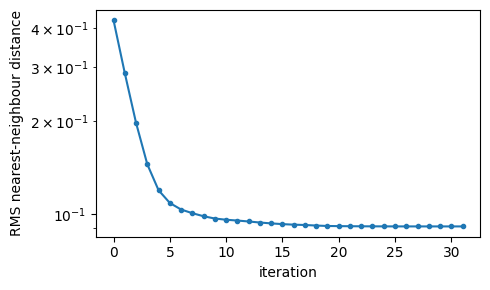

In [15]:
# check: a 30-degree motion, started from the identity and the difference of the means
Q30 = rot([1, 2, 2], 30).T
Ys = scan(Q30, t_true)
Qi, ti, hist = icp(X, Ys, np.eye(3), Ys.mean(0) - X.mean(0))
print(f"{len(hist) - 1} iterations; RMS {hist[0]:.4f} -> {hist[1]:.4f} -> {hist[2]:.4f} -> ... -> {hist[-1]:.4f}")
print(f"rotation error {angle_deg(Qi @ Q30.T):.2f} deg;  RMS never increased: {np.all(np.diff(hist) <= 1e-12)}")
plt.figure(figsize=(5, 3)); plt.semilogy(hist, "o-", ms=3); plt.xlabel("iteration"); plt.ylabel("RMS nearest-neighbour distance")
plt.tight_layout(); plt.show()

**(b)** Two questions about the run above. Why can the RMS never increase from one iteration to the next? And the scan noise is $0.01$: why does the final RMS stop near $0.09$ rather than near $0.01$, although the rotation is recovered to about half a degree?

In [16]:
# B3(b): how much of the final RMS is just the sampling gap between two different samples of the surface?
d, _ = cKDTree(make_fish(800, 2)).query(X)
print(f"RMS distance model -> another noiseless sample: {np.sqrt(np.mean(d ** 2)):.4f}")
print(f"noise alone would give sqrt(3)*0.01 = {np.sqrt(3) * 0.01:.4f}")

RMS distance model -> another noiseless sample: 0.0912
noise alone would give sqrt(3)*0.01 = 0.0173


**Your answer.**
1. The RMS never increases because both steps of an iteration decrease (or keep) the same objective Σᵢ minⱼ‖Qᵀxᵢ + t − yⱼ‖². Match: with Q, t fixed, every point takes its nearest scan point, so no other assignment can give a smaller sum of squared distances. Align: with the pairs fixed, Kabsch gives the minimum over all rigid motions, including the current one. The objective is bounded below by 0, so the iteration converges, but only to a local minimum.
2. The final RMS is ≈ 0.09 rather than 0.01 because the scan is a different sample of the surface: even with a perfect alignment, a model point has no scan point exactly next to it, only the nearest one. I measured the RMS nearest-neighbour distance between the model and a noiseless second sample: 0.091, which explains almost all of 0.09, while the noise alone would give only √3·0.01 ≈ 0.017. The RMS measures distance to the nearest point, not to the corresponding one, so it stays at the sampling gap even when the rotation is recovered to 0.5°.

**(c)** *Predict, then compute.* The **basin of attraction** of ICP is the set of starting errors from which it finds the right answer. Before running, predict the largest rotation angle from which ICP, started at the identity, still succeeds reliably. Then, for angles $0^\circ, 15^\circ, \dots, 180^\circ$ and the 20 random axes below, run ICP from the identity and the difference of the means, and report the fraction of successes (final rotation error below $2^\circ$) and the median final RMS of the failures. Could you detect a failure without knowing the truth?

**Your prediction** *(write it before running the next cell)*: ICP will likely fail if the initial rotation error is larger than 30-45 degrees, as it relies on local nearest neighbors. Once parts like the tail and fin are too far apart, it will get trapped in local minima.

In [17]:
axes = np.random.default_rng(7).standard_normal((20, 3))

In [18]:
angles = np.arange(0, 181, 15)

for ang in angles:
    successes = 0
    failures_rms, success_rms = [], []

    for axis in axes:
        Q_true_c = rot(axis, ang).T
        Y_c = scan(Q_true_c, t_true)

        # ICP from the identity and the difference of the means
        Q_i, t_i, hist = icp(X, Y_c, np.eye(3), Y_c.mean(0) - X.mean(0))
        err = angle_deg(Q_i @ Q_true_c.T)

        if err < 2.0:
            successes += 1
            success_rms.append(hist[-1])
        else:
            failures_rms.append(hist[-1])

    med_fail = np.median(failures_rms) if failures_rms else np.nan
    med_succ = np.median(success_rms) if success_rms else np.nan
    print(f"Angle {ang:3d}: success {successes / 20:5.1%}, "
          f"median final RMS of failures {med_fail:.4f}, of successes {med_succ:.4f}")

Angle   0: success 100.0%, median final RMS of failures nan, of successes 0.0910
Angle  15: success 100.0%, median final RMS of failures nan, of successes 0.0909
Angle  30: success 100.0%, median final RMS of failures nan, of successes 0.0908
Angle  45: success 100.0%, median final RMS of failures nan, of successes 0.0907
Angle  60: success 100.0%, median final RMS of failures nan, of successes 0.0907
Angle  75: success 100.0%, median final RMS of failures nan, of successes 0.0907
Angle  90: success 85.0%, median final RMS of failures 0.1954, of successes 0.0908
Angle 105: success 30.0%, median final RMS of failures 0.1948, of successes 0.0906
Angle 120: success 15.0%, median final RMS of failures 0.2104, of successes 0.0907
Angle 135: success  5.0%, median final RMS of failures 0.1990, of successes 0.0920
Angle 150: success  0.0%, median final RMS of failures 0.2104, of successes nan
Angle 165: success  0.0%, median final RMS of failures 0.2103, of successes nan
Angle 180: success  0.

**Your answer.**
ICP started from the identity succeeds in 100% of the runs up to 75°, in 85% at 90°, and then fails quickly: 30% at 105°, 15% at 120°, 5% at 135°, and 0% from 150° to 180°. My prediction (reliable up to about 30–45°) was too pessimistic.

Yes, a failure can be detected without the truth: all successful runs end with RMS ≈ 0.091 (the sampling gap from B3(b)), whereas the failures end with a median RMS of 0.19–0.21 (smallest about 0.14), so a final RMS clearly above 0.1 signals a local minimum. This works only because we know the success level from B3(b).

**(d)** *A better start, from Module 5.* The principal directions of the centred model (the right singular vectors $V_X$) and of the centred scan ($V_Y$) are the axes of the fish in the two frames, each determined only up to sign. Implement `pca_candidates(X, Y)`, which returns the four **rotations** $Q = V_X D V_Y^\top$ with $D$ a diagonal matrix of signs. (Why four and not eight?) Then implement `icp_pca(X, Y)`, which runs ICP from each candidate, with $\mathbf t = \bar{\mathbf y} - Q^\top\bar{\mathbf x}$ in row form, and keeps the run with the smallest final RMS. Repeat the sweep of (c) for angles $0^\circ, 30^\circ, \dots, 180^\circ$.

In [19]:
def pca_candidates(X, Y):
    # principal directions of the centred model and scan (right singular vectors)
    _, _, Vt_x = np.linalg.svd(X - X.mean(0))
    _, _, Vt_y = np.linalg.svd(Y - Y.mean(0))
    Vx, Vy = Vt_x.T.copy(), Vt_y.T.copy()
    # make both frames right-handed (det = +1); otherwise Vx D Vy^T may be a reflection
    if np.linalg.det(Vx) < 0: Vx[:, -1] *= -1
    if np.linalg.det(Vy) < 0: Vy[:, -1] *= -1
    # the four sign matrices with det D = +1 (the other four have det = -1)
    Ds = [np.diag(d) for d in ([1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1])]
    return [Vx @ D @ Vy.T for D in Ds]

def icp_pca(X, Y):
    # run ICP from every candidate and keep the run with the smallest final RMS
    best_rms, best_result = float('inf'), None
    for Q_cand in pca_candidates(X, Y):
        t_cand = Y.mean(0) - X.mean(0) @ Q_cand
        Q_res, t_res, hist = icp(X, Y, Q_cand, t_cand)
        if hist[-1] < best_rms:
            best_rms, best_result = hist[-1], (Q_res, t_res, hist)
    return best_result

# check: all four candidates are rotations, and how far each one is from the truth (60 degrees about axes[0])
Q60 = rot(axes[0], 60).T
Y60 = scan(Q60, t_true)
cands = pca_candidates(X, Y60)
print("det of the candidates:", [round(np.linalg.det(Qc)) for Qc in cands])
print("angle of each candidate from the truth (deg):", [round(angle_deg(Qc @ Q60.T), 1) for Qc in cands])

# the sweep
for ang in np.arange(0, 181, 30):
    successes = 0
    failures_rms = []
    for axis in axes:
        Q_true_c = rot(axis, ang).T
        Y_c = scan(Q_true_c, t_true)
        Q_i, t_i, hist = icp_pca(X, Y_c)
        if angle_deg(Q_i @ Q_true_c.T) < 2.0:
            successes += 1
        else:
            failures_rms.append(hist[-1])
    med_fail = np.median(failures_rms) if failures_rms else np.nan
    print(f"Angle {ang:3d}: success {successes / 20:5.1%}, median fail RMS {med_fail:.4f}")

det of the candidates: [1, 1, 1, 1]
angle of each candidate from the truth (deg): [np.float64(1.9), np.float64(178.2), np.float64(179.6), np.float64(179.6)]
Angle   0: success 100.0%, median fail RMS nan
Angle  30: success 100.0%, median fail RMS nan
Angle  60: success 100.0%, median fail RMS nan
Angle  90: success 100.0%, median fail RMS nan
Angle 120: success 100.0%, median fail RMS nan
Angle 150: success 100.0%, median fail RMS nan
Angle 180: success 100.0%, median fail RMS nan


**Your answer.** There are four candidates and not eight because Q must be a rotation (det Q = +1): of the 2³ = 8 sign matrices D, exactly four have det D = +1 (the others are reflections). For this to hold, both frames Vx and Vy must be right-handed (det = +1), so I flip the last column of Vx or Vy when its determinant is −1; without this step, Vx D Vyᵀ can be a reflection for all four D.

The sweep shows that icp_pca succeeds in 100% of the runs for all angles 0°, 30°, …, 180°, while ICP from the identity fails from about 105° (see (c)). PCA aligns the principal axes of the fish, so one of the four candidates is within a few degrees of the truth (1.9° in the run with a 60° rotation), and ICP only has to polish it; the choice by the smallest final RMS picks that run.

**(e)** *Predict, then compute.* A real scan sees only part of the object, and picks up stray points. The scan below sees only the side of the fish with $y > -0.3$ (in the model frame), and 10% extra points scattered uniformly around it. Start ICP from the identity and the difference of the **medians** (why not the means?), with up to 300 iterations, and sweep `trim` over $1.0, 0.9, \dots, 0.3$. Report the rotation error and the fish RMS against `truth30 = move(X, Q30, t_true)`. Before running, predict which values of `trim` will work, using the fraction of the fish the scanner sees (printed below).

In [20]:
visible = lambda P: P[:, 1] > -0.3
Yv = scan(Q30, t_true, keep=visible)
r = np.random.default_rng(52)
lo, hi = Yv.min(0) - 0.5, Yv.max(0) + 0.5
Yp = np.vstack([Yv, lo + (hi - lo) * r.random((len(Yv) // 10, 3))])
Yp = Yp[r.permutation(len(Yp))]
truth30 = move(X, Q30, t_true)
print(f"scan: {len(Yv)} surface points + {len(Yp) - len(Yv)} stray points; "
      f"the scanner sees {visible(make_fish(800, 2)).mean():.1%} of the fish")

scan: 582 surface points + 58 stray points; the scanner sees 72.8% of the fish


**Your prediction** *(write it before running the next cell)*: I did not write a prediction before running the cell. Afterwards I reasoned as follows: the scan sees about 72.8% of the fish (the value printed above), so the best trim should be somewhat below this fraction, so that the unseen part and the stray points are discarded.

In [21]:
# start from the identity and the difference of the medians; up to 300 iterations
print("trim | rotation error (deg) | fish RMS")
for tr in np.arange(1.0, 0.2, -0.1):
    Q_e, t_e, hist_e = icp(X, Yp, np.eye(3), np.median(Yp, axis=0) - np.median(X, axis=0),
                           iters=300, trim=tr)
    err = angle_deg(Q_e @ Q30.T)
    f_rms = rms(X @ Q_e + t_e, truth30)
    print(f"{tr:.1f}  | {err:9.2f} | {f_rms:.4f}")

trim | rotation error (deg) | fish RMS
1.0  |     15.92 | 0.2810
0.9  |      7.63 | 0.1581
0.8  |      3.05 | 0.0684
0.7  |      1.80 | 0.0321
0.6  |      1.02 | 0.0184
0.5  |      9.14 | 0.2415
0.4  |     11.11 | 0.2828
0.3  |      5.03 | 0.1331


**Your answer.** In the sweep, trim = 0.6 and 0.7 work best (rotation error 1.0° and 1.8°, fish RMS 0.018 and 0.032). Trim = 1.0 gives 15.92°, trim = 0.8 gives 3.05°, and trim = 0.5 and 0.4 are bad again (9.14° and 11.11°). The best values are consistent with the visible fraction 0.73: the trim should be somewhat below it, so that the matches of the unseen part and of the stray points are discarded, while all the visible points stay in. Why small trims fail again, and why the dependence on trim is not monotone, we did not investigate.

We start from the medians because the scan sees only one side of the fish and has stray points: the mean of the scan is shifted towards the visible side and is pulled by the stray points, whereas the median is less sensitive to the stray points.

**(f)** *Predict, then measure.* One ICP iteration does three things: query $n$ points in the tree, form the $3\times3$ matrix $\widetilde X^\top\widetilde Y$, and take its SVD; building the tree is done once. Predict how each cost grows with $n$ (model and scan both of size $n$), and which dominates. Then time them, on clouds that are already roughly aligned, for $n = 10^3, 10^4, 10^5$. Finally estimate the time of brute-force matching (all $n^2$ distances) for $n = 10^4$ from a $2000\times10^4$ block.

**Your prediction** *(write it before running the next cell)*:
1. KD-tree query: O(n log n).
2. Matrix product XᵀY: O(n).
3. SVD of a 3×3 matrix: O(1) (constant time).

The KD-tree query will dominate the execution time as n grows.

In [22]:
n_vals = [10**3, 10**4, 10**5]

for n_test in n_vals:
    # two clouds that are already roughly aligned: the model moved by the true motion, and a scan
    A = make_fish(n_test, seed=1) @ Q_true + t_true
    B = scan(Q_true, t_true, n=n_test, seed=2)

    t0 = time.perf_counter(); tree = cKDTree(B);       t_build = time.perf_counter() - t0   # done once
    t0 = time.perf_counter(); _, idxs = tree.query(A); t_query = time.perf_counter() - t0
    B_act = B[idxs]
    t0 = time.perf_counter(); H = (A - A.mean(0)).T @ (B_act - B_act.mean(0)); t_mat = time.perf_counter() - t0
    t0 = time.perf_counter(); np.linalg.svd(H);        t_svd = time.perf_counter() - t0

    print(f"n={n_test:<7}: build {t_build * 1e3:8.2f} ms | query {t_query * 1e3:8.2f} ms | "
          f"matrix {t_mat * 1e3:7.3f} ms | SVD {t_svd * 1e3:7.3f} ms")

# brute-force matching for n = 10^4, estimated from a 2000 x 10^4 block
# (note: this allocates about 0.5 GB)
A_small = np.random.randn(2000, 3)
B_large = np.random.randn(10000, 3)
t0 = time.perf_counter()
dists = np.sum((A_small[:, None, :] - B_large[None, :, :]) ** 2, axis=-1)
nearest = dists.argmin(axis=1)
t_brute = time.perf_counter() - t0
print(f"\nBrute force, block 2000 x 10^4: {t_brute:.2f} s;  estimate for 10^4 x 10^4: {t_brute * 5:.1f} s")

n=1000   : build     0.48 ms | query     1.40 ms | matrix   0.205 ms | SVD   0.107 ms
n=10000  : build     4.65 ms | query    15.14 ms | matrix   1.159 ms | SVD   0.128 ms
n=100000 : build   101.89 ms | query   247.97 ms | matrix  11.865 ms | SVD   0.159 ms

Brute force, block 2000 x 10^4: 1.35 s;  estimate for 10^4 x 10^4: 6.8 s


**Your answer.** The prediction is confirmed qualitatively: the KD-tree query dominates at every n (for n = 10⁵: 248 ms for the query, 11.9 ms for the matrix product, 0.16 ms for the SVD). The matrix product grows roughly linearly for large n (×5.7 from n = 10³ to 10⁴ and ×10.2 from 10⁴ to 10⁵), and the SVD time is negligible and does not grow with n (0.11 to 0.16 ms). The query time grows ×10.8 and then ×16.4 per factor 10 in n, so it is not exactly n log n (which would give about ×13 and ×12.5); a possible reason is overhead at small n and cache effects at large n, but we did not check this. Building the tree is done once and is cheaper than one query (102 ms against 248 ms for n = 10⁵).

Brute-force matching for n = 10⁴ costs about 6.8 s per iteration (1.35 s for the 2000 × 10⁴ block, times 5), against about 15 ms for the KD-tree query, so about 450 times more; it also needs all n² distances, so it is unusable for larger n.

---
# Extension - attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E2. Shape from a moving camera: Tomasi-Kanade

*This topic was not lectured; the introduction below is all you need.*

A camera moves around a rigid object and tracks $n$ points through $F$ frames. Far from the object the camera is close to **orthographic**: in frame $f$ it sees the point $\mathbf p$ (a column vector in the object frame) at the image coordinates $(\mathbf i_f^\top\mathbf p + a_f,\ \mathbf j_f^\top\mathbf p + b_f)$, where $\mathbf i_f, \mathbf j_f$ are the first two rows of the camera's rotation (two orthonormal vectors) and $(a_f, b_f)$ is a shift. Stack the $2F$ image rows into the **measurement matrix** $W\in\mathbb R^{2F\times n}$ (column $p$ holds the track of point $p$). After subtracting each row's mean,
$$\widetilde W = \underbrace{\begin{pmatrix}\mathbf i_1^\top\\ \mathbf j_1^\top\\ \vdots\\ \mathbf j_F^\top\end{pmatrix}}_{M\ (2F\times3)}\ \underbrace{\begin{pmatrix}\widetilde{\mathbf p}_1 & \cdots & \widetilde{\mathbf p}_n\end{pmatrix}}_{S\ (3\times n)} + \text{noise},$$
so $\widetilde W$ has rank 3 in the absence of noise (Tomasi and Kanade, 1992). The camera motion $M$ and the shape $S$ are both unknown; the SVD recovers them.

In [23]:
P_true = make_fish(300, seed=3)            # the object (unknown to the method)
F = 15
cams = [rot([1, 0, 0], 20 * np.sin(2 * np.pi * f / F)) @ rot([0, 0, 1], -40 + 80 * f / (F - 1)) for f in range(F)]
shifts = np.random.default_rng(8).uniform(-1, 1, (2 * F, 1))

def measurements(sd):
    W = np.vstack([P_true @ C[:2].T for C in cams]).reshape(F, -1, 2).transpose(0, 2, 1).reshape(2 * F, -1)
    return W + shifts + sd * np.random.default_rng(9).standard_normal((2 * F, len(P_true)))

W = measurements(0.003)
print("W:", W.shape)

W: (30, 300)


**(a)** *Predict, then compute.* Centre the rows of $W$ and compute its singular values. Predict how many stand out, and the level of the others, using the noise floor $\text{sd}(\sqrt{m} + \sqrt{n})$ of Notebook A (A2). Compare.

**Your prediction** *(write it before running the next cell)*:

In [24]:
# YOUR CODE HERE
raise NotImplementedError

NotImplementedError: 

**Your answer.** *Write it here.*

**(b)** Set $\widehat M = U_3\Sigma_3^{1/2}$ and $\widehat S = \Sigma_3^{1/2}V_3^\top$, so that $\widehat M\widehat S$ is the best rank-3 approximation of $\widetilde W$. Show that $\widehat MA$ and $A^{-1}\widehat S$ fit the data equally well for **every** invertible $3\times3$ matrix $A$. Check numerically that the rows of $\widehat M$ are not pairs of orthonormal vectors, so $\widehat S$ is the shape only up to an unknown linear distortion.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

**Your answer.** *Write it here.*

**(c)** *The metric upgrade.* We want $A$ such that the rows of $M = \widehat MA$ satisfy $\mathbf i_f^\top\mathbf i_f = \mathbf j_f^\top\mathbf j_f = 1$ and $\mathbf i_f^\top\mathbf j_f = 0$. With $L := AA^\top$ these conditions are **linear** in the six entries of the symmetric matrix $L$: for instance $\widehat{\mathbf m}_{2f-1}^\top L\,\widehat{\mathbf m}_{2f-1} = 1$. Set up the $3F\times6$ system, solve it by least squares (`np.linalg.lstsq`), check that $L$ is positive definite, and recover $A$ as its Cholesky factor (Module 4). Then compute $S = A^{-1}\widehat S$ with a triangular solve and check the orthonormality conditions for $M$.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

**Your answer.** *Write it here.*

**(d)** Compare the recovered shape (the rows of $S^\top$) with the true centred object, after aligning them with `procrustes` and with `kabsch` from B1-B2. Which of the two must you use here, and why? (*Hint:* is the mirror image of the object, seen by the mirrored camera, consistent with the same images?) Then mirror the reconstruction, $M \to MD$, $S \to DS$ with $D = \operatorname{diag}(1,1,-1)$: check that it fits the images exactly as well and still satisfies the orthonormality conditions, and align it to the truth in both ways. Repeat for $\text{sd} = 0.03$ and report the RMS shape error relative to the size of the object.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

**Your answer.** *Write it here.*

---
**Before you submit:** run `Kernel -> Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.